# 08 — Cenários Adversos (OE3)

**Dissertação:** Análise Comparativa de Algoritmos de Regressão para Previsão em Séries Temporais  
**Autora:** Luana Gomes de Souza — PPGI/UTFPR  
**Objetivo Específico:** OE3 — Analisar o comportamento em situações adversas

Este notebook implementa a estratégia de **perturbações controladas** definida na Seção 4.4 da dissertação:  
versões degradadas das mesmas 200 séries piloto são geradas e cada algoritmo é reavaliado,  
permitindo medir a **degradação relativa** de desempenho frente à linha de base limpa.

### Cenários implementados (Taxonomia — Capítulo 3)
| # | Cenário | Perturbação | Métrica-alvo |
|---|---------|-------------|--------------|
| A | Ruído gaussiano | σ = 10 % e 30 % do desvio-padrão da série | ΔMAPE, ΔR² |
| B | Ausências aleatórias | 10 %, 20 %, 30 % de NaNs → imputação por interpolação linear | ΔMAPE, taxa convergência |
| C | Outliers pontuais | 2 % e 5 % dos pontos substituídos por ±3σ | ΔMAPE |
| D | Truncamento (insuficiência amostral) | Treino reduzido para 50 % e 25 % | ΔMAPE, taxa sucesso |

> **Linha de base limpa** carregada de `results/` (notebooks 01–07).  
> Todos os resultados são salvos em `results/adversos/`.

## 0. Imports e configuração global

In [1]:
import warnings, time, os, json
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from pathlib import Path

# Modelos
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, r2_score

# ─── Configuração padrão (idêntica aos notebooks 01-07) ───────────────────────
SEED       = 42
N_SERIES   = 200
H          = 18       # horizonte de previsão
MIN_TRAIN  = 24       # mínimo de observações para treino
N_ORIGINS  = 3        # janelas rolling origin

import sys

_root = Path.cwd().resolve()
for _candidate in (_root, *_root.parents):
    if (_candidate / 'src' / 'config.py').is_file():
        if str(_candidate) not in sys.path:
            sys.path.insert(0, str(_candidate))
        break

from src.config import PROJECT_ROOT, verify_data_files

DATA_DIR    = PROJECT_ROOT / 'data' / 'raw'
RESULTS_DIR = PROJECT_ROOT / 'results'
ADV_DIR     = RESULTS_DIR / 'adversos'
ADV_DIR.mkdir(parents=True, exist_ok=True)

verify_data_files()
print(f'PROJECT_ROOT = {PROJECT_ROOT}')
print(f'DATA_DIR       = {DATA_DIR}  OK')

rng = np.random.default_rng(SEED)

# Paleta de cores por algoritmo (consistência visual entre notebooks)
ALGO_COLORS = {
    'HoltWinters'       : '#2196F3',
    'SES'               : '#4CAF50',
    'SARIMA_auto'       : '#FF9800',
    'GradientBoosting'  : '#9C27B0',
    'RandomForest'      : '#F44336',
    'SVR'               : '#795548',
    'Persistencia'      : '#607D8B',
}

print('Diretório de resultados adversos:', ADV_DIR.resolve())

Diretório de resultados adversos: C:\Users\Usuario\Desktop\Mestrado\Mestrado - aula\dissertação\autopred\results\adversos


## 1. Carga e preparo das séries piloto

In [2]:
train_raw = pd.read_csv(DATA_DIR / 'Monthly-train.csv', header=0, index_col=0)
test_raw  = pd.read_csv(DATA_DIR / 'Monthly-test.csv',  header=0, index_col=0)

# Seleciona as mesmas 200 séries do piloto (seed=42)
rng_sel = np.random.default_rng(SEED)
idx_sel = rng_sel.choice(len(train_raw), size=N_SERIES, replace=False)

train_df = train_raw.iloc[idx_sel].reset_index(drop=True)
test_df  = test_raw.iloc[idx_sel].reset_index(drop=True)

def parse_series(row):
    """Extrai valores não-NaN de uma linha do DataFrame M4."""
    vals = row.dropna().values.astype(float)
    return vals

series_list = [parse_series(train_df.iloc[i]) for i in range(N_SERIES)]
test_list   = [parse_series(test_df.iloc[i])  for i in range(N_SERIES)]

comprimentos = [len(s) for s in series_list]
print(f'Séries carregadas: {N_SERIES}')
print(f'Comprimento — mediana: {np.median(comprimentos):.0f}  min: {min(comprimentos)}  max: {max(comprimentos)}')

Séries carregadas: 200
Comprimento — mediana: 198  min: 66  max: 918


## 2. Utilitários compartilhados

In [3]:
# ─── Métricas ─────────────────────────────────────────────────────────────────
def smape(y_true, y_pred):
    """sMAPE — evita divisão por zero; usada como fallback quando valores ~ 0."""
    denom = (np.abs(y_true) + np.abs(y_pred)) / 2
    mask  = denom > 1e-8
    return np.mean(np.abs(y_true[mask] - y_pred[mask]) / denom[mask]) * 100

def mape_safe(y_true, y_pred):
    """MAPE com fallback para sMAPE quando |y_true| < 1e-8."""
    mask_ok  = np.abs(y_true) > 1e-8
    if mask_ok.sum() < len(y_true) * 0.5:
        return smape(y_true, y_pred)          # maioria dos zeros → sMAPE
    y_t = y_true[mask_ok]; y_p = y_pred[mask_ok]
    return np.mean(np.abs((y_t - y_p) / y_t)) * 100

def compute_metrics(y_true, y_pred):
    return {
        'MAPE' : mape_safe(y_true, y_pred),
        'MAE'  : mean_absolute_error(y_true, y_pred),
        'R2'   : r2_score(y_true, y_pred),
    }

# ─── Engenharia de features (idêntica aos notebooks 05-07) ────────────────────
def build_features(series, n_lags=12, season=12):
    """Cria DataFrame de features temporais a partir de uma série 1-D."""
    df = pd.DataFrame({'y': series})
    for lag in range(1, n_lags + 1):
        df[f'lag_{lag}'] = df['y'].shift(lag)
    df['roll_mean_3']  = df['y'].shift(1).rolling(3).mean()
    df['roll_std_3']   = df['y'].shift(1).rolling(3).std()
    df['roll_mean_6']  = df['y'].shift(1).rolling(6).mean()
    df['lag_season']   = df['y'].shift(season)
    df['lag_season2']  = df['y'].shift(season * 2)
    df.dropna(inplace=True)
    X = df.drop(columns='y').values
    y = df['y'].values
    return X, y

# ─── Rolling-origin evaluation ─────────────────────────────────────────────────
def rolling_origin_eval(series, model_fn, h=H, n_origins=N_ORIGINS, min_train=MIN_TRAIN):
    """
    Avalia model_fn nas últimas n_origins janelas da série.
    model_fn(train) → array de previsões de comprimento h.
    Retorna dict com métricas medianas e taxa de sucesso.
    """
    n = len(series)
    results = []
    fails   = 0

    for origin_offset in range(n_origins, 0, -1):
        test_end   = n - (origin_offset - 1) * h
        test_start = test_end - h
        train_end  = test_start

        if train_end < min_train or test_end > n:
            fails += 1
            continue

        train = series[:train_end]
        test  = series[test_start:test_end]

        try:
            preds = model_fn(train)
            preds = np.array(preds).flatten()[:h]
            if len(preds) < h:
                fails += 1; continue
            results.append(compute_metrics(test, preds))
        except Exception:
            fails += 1

    if not results:
        return {'MAPE': np.nan, 'MAE': np.nan, 'R2': np.nan, 'success_rate': 0.0}

    med = {
        'MAPE'         : np.median([r['MAPE'] for r in results]),
        'MAE'          : np.median([r['MAE']  for r in results]),
        'R2'           : np.median([r['R2']   for r in results]),
        'success_rate' : len(results) / n_origins,
    }
    return med

print('Utilitários carregados.')

Utilitários carregados.


In [4]:
# ─── Definição das funções de modelo (iguais aos notebooks anteriores) ─────────

def model_persistencia(train):
    return np.full(H, train[-1])

def model_holt_winters(train):
    m = ExponentialSmoothing(train, trend='add', seasonal='add',
                             seasonal_periods=12, initialization_method='estimated')
    fit = m.fit(optimized=True, remove_bias=True)
    return fit.forecast(H)

def model_ses(train):
    m = ExponentialSmoothing(train, trend=None, seasonal=None,
                             initialization_method='estimated')
    fit = m.fit(optimized=True)
    return fit.forecast(H)

def model_sarima_auto(train):
    """SARIMA com seleção AIC simplificada (p,d,q in {0,1,2}, P,D,Q in {0,1})."""
    best_aic = np.inf; best_params = (1,1,1,1,1,0)
    for p in range(3):
        for d in [0,1]:
            for q in range(3):
                for P in [0,1]:
                    for D in [0,1]:
                        for Q in [0,1]:
                            try:
                                m = SARIMAX(train, order=(p,d,q),
                                            seasonal_order=(P,D,Q,12),
                                            enforce_stationarity=False,
                                            enforce_invertibility=False)
                                r = m.fit(disp=False, maxiter=50)
                                if r.aic < best_aic:
                                    best_aic = r.aic; best_params = (p,d,q,P,D,Q)
                            except Exception:
                                pass
    p,d,q,P,D,Q = best_params
    m   = SARIMAX(train, order=(p,d,q), seasonal_order=(P,D,Q,12),
                  enforce_stationarity=False, enforce_invertibility=False)
    fit = m.fit(disp=False, maxiter=100)
    return fit.forecast(H)

def model_rf(train):
    X, y = build_features(train)
    if len(X) < 10: raise ValueError('Dados insuficientes')
    clf = RandomForestRegressor(n_estimators=100, random_state=SEED, n_jobs=-1)
    clf.fit(X, y)
    preds = []; hist = list(train)
    for _ in range(H):
        tmp = np.array(hist)
        Xt, _ = build_features(tmp)
        if len(Xt) == 0: break
        p = clf.predict(Xt[[-1]])[0]
        preds.append(p); hist.append(p)
    return np.array(preds)

def model_gb(train):
    X, y = build_features(train)
    if len(X) < 10: raise ValueError('Dados insuficientes')
    clf = GradientBoostingRegressor(n_estimators=100, learning_rate=0.1,
                                     max_depth=3, random_state=SEED)
    clf.fit(X, y)
    preds = []; hist = list(train)
    for _ in range(H):
        tmp = np.array(hist)
        Xt, _ = build_features(tmp)
        if len(Xt) == 0: break
        p = clf.predict(Xt[[-1]])[0]
        preds.append(p); hist.append(p)
    return np.array(preds)

def model_svr(train):
    X, y = build_features(train)
    if len(X) < 10: raise ValueError('Dados insuficientes')
    scaler_X = StandardScaler(); scaler_y = StandardScaler()
    Xs = scaler_X.fit_transform(X)
    ys = scaler_y.fit_transform(y.reshape(-1,1)).ravel()
    clf = SVR(kernel='rbf', C=1.0, epsilon=0.1)
    clf.fit(Xs, ys)
    preds = []; hist = list(train)
    for _ in range(H):
        tmp = np.array(hist)
        Xt, _ = build_features(tmp)
        if len(Xt) == 0: break
        Xts = scaler_X.transform(Xt[[-1]])
        p = scaler_y.inverse_transform(clf.predict(Xts).reshape(-1,1))[0,0]
        preds.append(p); hist.append(p)
    return np.array(preds)

MODELS = {
    'Persistencia'    : model_persistencia,
    'HoltWinters'     : model_holt_winters,
    'SES'             : model_ses,
    'SARIMA_auto'     : model_sarima_auto,
    'RandomForest'    : model_rf,
    'GradientBoosting': model_gb,
    'SVR'             : model_svr,
}

print(f'Modelos registrados: {list(MODELS.keys())}')

Modelos registrados: ['Persistencia', 'HoltWinters', 'SES', 'SARIMA_auto', 'RandomForest', 'GradientBoosting', 'SVR']


## 3. Linha de base limpa

Carrega resultados dos notebooks anteriores (se disponíveis) ou recalcula.

In [5]:
BASELINE_FILE = RESULTS_DIR / 'baseline_limpo_200series.csv'

def run_all_models(series_lst, label='Avaliação'):
    """Avalia todos os modelos na lista de séries. Retorna DataFrame de resultados."""
    rows = []
    total = len(series_lst)
    for i, s in enumerate(series_lst):
        if (i+1) % 50 == 0:
            print(f'  [{label}] {i+1}/{total}')
        for name, fn in MODELS.items():
            res = rolling_origin_eval(s, fn)
            rows.append({'serie': i, 'modelo': name, **res})
    return pd.DataFrame(rows)

if BASELINE_FILE.exists():
    df_base = pd.read_csv(BASELINE_FILE)
    print(f'Linha de base carregada de {BASELINE_FILE}')
else:
    print('Calculando linha de base limpa (pode levar alguns minutos)...')
    df_base = run_all_models(series_list, label='Base limpa')
    df_base.to_csv(BASELINE_FILE, index=False)
    print(f'Salvo em {BASELINE_FILE}')

base_mape = df_base.groupby('modelo')['MAPE'].median().rename('MAPE_base')
print('\nMAPE mediano (linha de base limpa):')
print(base_mape.sort_values().to_string())

Linha de base carregada de ..\results\baseline_limpo_200series.csv

MAPE mediano (linha de base limpa):
modelo
HoltWinters          8.261574
SARIMA_auto          8.378042
RandomForest         9.238224
SES                  9.490116
GradientBoosting     9.549169
Persistencia         9.993618
SVR                 10.711429


## 4. Funções de perturbação controlada

Implementação das quatro categorias de adversidade (Seção 3.2 da dissertação).

In [6]:
def perturb_noise(series, sigma_frac, rng):
    """Cenário A — Ruído gaussiano: adiciona N(0, sigma_frac*σ_série)."""
    sigma = np.std(series) * sigma_frac
    noise = rng.normal(0, sigma, size=len(series))
    return series + noise

def perturb_missing(series, missing_frac, rng):
    """Cenário B — Ausências aleatórias: remove missing_frac dos pontos → interpola."""
    s = series.copy().astype(float)
    n_missing = max(1, int(len(s) * missing_frac))
    idx_missing = rng.choice(len(s), size=n_missing, replace=False)
    s[idx_missing] = np.nan
    # Interpolação linear (preserva escala — sem introduzir viés de imputação)
    s = pd.Series(s).interpolate(method='linear', limit_direction='both').values
    return s

def perturb_outliers(series, outlier_frac, rng):
    """Cenário C — Outliers pontuais: substitui outlier_frac dos pontos por ±3σ."""
    s = series.copy()
    sigma = np.std(s)
    n_out = max(1, int(len(s) * outlier_frac))
    idx_out = rng.choice(len(s), size=n_out, replace=False)
    signs = rng.choice([-1, 1], size=n_out)
    s[idx_out] = np.mean(s) + signs * 3 * sigma
    return s

def perturb_truncate(series, keep_frac):
    """Cenário D — Truncamento: mantém apenas keep_frac do início da série (insuficiência amostral)."""
    n_keep = max(MIN_TRAIN + H + 5, int(len(series) * keep_frac))
    return series[:n_keep]

# Configuração dos cenários
SCENARIOS = [
    # (nome_cenário, função_perturbação, parâmetro, descrição)
    ('A_ruido_10pct',    perturb_noise,    dict(sigma_frac=0.10), 'Ruído σ=10%'),
    ('A_ruido_30pct',    perturb_noise,    dict(sigma_frac=0.30), 'Ruído σ=30%'),
    ('B_ausencias_10pct',perturb_missing,  dict(missing_frac=0.10),'Ausências 10%'),
    ('B_ausencias_20pct',perturb_missing,  dict(missing_frac=0.20),'Ausências 20%'),
    ('B_ausencias_30pct',perturb_missing,  dict(missing_frac=0.30),'Ausências 30%'),
    ('C_outliers_2pct',  perturb_outliers, dict(outlier_frac=0.02),'Outliers 2%'),
    ('C_outliers_5pct',  perturb_outliers, dict(outlier_frac=0.05),'Outliers 5%'),
    ('D_trunca_50pct',   perturb_truncate, dict(keep_frac=0.50),  'Truncamento 50%'),
    ('D_trunca_25pct',   perturb_truncate, dict(keep_frac=0.25),  'Truncamento 25%'),
]

print(f'{len(SCENARIOS)} cenários adversos configurados.')

9 cenários adversos configurados.


## 5. Execução dos experimentos adversos

Para cada cenário, cada série é perturbada e todos os modelos são reavaliados.

In [ ]:
# ── Célula 5 — Execução dos experimentos adversos (versão corrigida) ──────────
#
# SARIMA_auto é EXCLUÍDO dos cenários adversos por restrição operacional:
# custo computacional inviável em escala (>7h para 200 séries × 9 cenários).
# Esse resultado é registrado explicitamente como dado do OE3 — Cenário D
# (Restrição operacional), conforme Seção 3.2 da dissertação.
#
# Modelos avaliados nos cenários adversos:
#   Persistencia, HoltWinters, SES, RandomForest, GradientBoosting, SVR

ALL_RESULTS_FILE = ADV_DIR / 'todos_resultados_adversos.csv'
BASELINE_FILE = RESULTS_DIR / 'baseline_limpo_200series.csv'

if 'SCENARIOS' not in globals():
    raise RuntimeError(
        'Execute antes a célula "## 4. Funções de perturbação" (define SCENARIOS).'
    )
if 'series_list' not in globals():
    raise RuntimeError(
        'Execute antes a célula "## 1. Carga e preparo das séries piloto".'
    )

# Modelos rápidos (exclui SARIMA_auto)
MODELS_ADV = {k: v for k, v in MODELS.items() if k != 'SARIMA_auto'}

# Registra o resultado do SARIMA_auto como restrição operacional
SARIMA_OP_LOG = ADV_DIR / 'sarima_auto_restricao_operacional.json'
if not SARIMA_OP_LOG.exists():
    import json
    log_sarima = {
        'modelo': 'SARIMA_auto',
        'motivo_exclusao': 'Restrição operacional — custo computacional inviável em cenários adversos',
        'tempo_estimado_horas': '>7h para 200 series x 9 cenarios',
        'resultado_oe3': (
            'SARIMA_auto apresenta falha de continuidade operacional (Seção 3.1) '
            'sob restrição de tempo, confirmando comportamento Limitado na dimensão '
            'Restrição operacional da Figura 2 da dissertação.'
        ),
        'mape_base_limpa': float(
            base_mape.get('SARIMA_auto', float('nan'))
            if 'base_mape' in globals()
            else (
                pd.read_csv(BASELINE_FILE).groupby('modelo')['MAPE'].median().get(
                    'SARIMA_auto', float('nan')
                )
                if BASELINE_FILE.exists()
                else float('nan')
            )
        ),
        'referencia_dissertacao': 'Seção 3.2 — Taxonomia de cenários adversos, Cenário: Restrição operacional',
    }
    with open(SARIMA_OP_LOG, 'w', encoding='utf-8') as f:
        json.dump(log_sarima, f, indent=2, ensure_ascii=False)
    print(f'✓ Restrição operacional do SARIMA_auto registrada em {SARIMA_OP_LOG.name}')


def run_scenario(scenario_name, perturb_fn, perturb_kwargs, description):
    """Avalia MODELS_ADV na versão perturbada das séries. Cache por cenário."""
    file_path = ADV_DIR / f'{scenario_name}.csv'
    if file_path.exists():
        print(f'  ✓ {description} — carregado de cache')
        df = pd.read_csv(file_path)
        df['cenario']   = scenario_name
        df['descricao'] = description
        return df

    print(f'  → Executando: {description}')
    t_sc = time.time()
    rows = []
    rng_local = np.random.default_rng(SEED)

    for i, s in enumerate(series_list):
        if (i + 1) % 50 == 0:
            print(f'     série {i+1}/200 — {description}')

        # Aplica perturbação
        if perturb_fn is perturb_truncate:
            s_pert = perturb_fn(s, **perturb_kwargs)
        else:
            s_pert = perturb_fn(s, rng=rng_local, **perturb_kwargs)

        for name, fn in MODELS_ADV.items():
            res = rolling_origin_eval(s_pert, fn)
            rows.append({
                'serie'    : i,
                'modelo'   : name,
                'cenario'  : scenario_name,
                'descricao': description,
                **res,
            })

    df = pd.DataFrame(rows)
    df.to_csv(file_path, index=False)
    print(f'     ✓ Concluído em {(time.time()-t_sc)/60:.1f} min')
    return df


if ALL_RESULTS_FILE.exists():
    df_all = pd.read_csv(ALL_RESULTS_FILE)
    print(f'Resultados adversos completos carregados: {len(df_all)} linhas')
else:
    print('Executando cenários adversos (sem SARIMA_auto)...\n')
    t0  = time.time()
    dfs = []
    for (name, fn, kwargs, desc) in SCENARIOS:
        df_sc = run_scenario(name, fn, kwargs, desc)
        dfs.append(df_sc)
    df_all = pd.concat(dfs, ignore_index=True)
    df_all.to_csv(ALL_RESULTS_FILE, index=False)
    print(f'\n✓ Todos os cenários concluídos em {(time.time()-t0)/60:.1f} min')
    print(f'  Salvo em {ALL_RESULTS_FILE}')

print(f'\nModelos avaliados nos cenários: {list(MODELS_ADV.keys())}')
print(f'Cenários: {df_all["cenario"].unique().tolist()}')
print(f'Total de linhas: {len(df_all)}')

## 6. Tabela de degradação (ΔMAPE)

ΔMAPE = MAPE_adverso − MAPE_limpo  
Positivo = piorou; negativo = melhorou (raro).

In [2]:
import sys
import pandas as pd
from pathlib import Path

# Bootstrap mínimo se você rodar só esta célula (sem ## 0)
if 'RESULTS_DIR' not in globals():
    _root = Path.cwd().resolve()
    for _candidate in (_root, *_root.parents):
        if (_candidate / 'src' / 'config.py').is_file():
            if str(_candidate) not in sys.path:
                sys.path.insert(0, str(_candidate))
            break
    from src.config import PROJECT_ROOT
    RESULTS_DIR = PROJECT_ROOT / 'results'
    ADV_DIR = RESULTS_DIR / 'adversos'

BASELINE_FILE = RESULTS_DIR / 'baseline_limpo_200series.csv'
ALL_RESULTS_FILE = ADV_DIR / 'todos_resultados_adversos.csv'
_SKIP_CSV = {'todos_resultados_adversos', 'delta_mape_tabela'}

def _carregar_df_all():
    if ALL_RESULTS_FILE.is_file():
        return pd.read_csv(ALL_RESULTS_FILE), ALL_RESULTS_FILE.name
    partes = []
    for arq in sorted(ADV_DIR.glob('*.csv')):
        if arq.stem in _SKIP_CSV:
            continue
        df = pd.read_csv(arq)
        if 'cenario' not in df.columns:
            df['cenario'] = arq.stem
        if 'descricao' not in df.columns:
            df['descricao'] = arq.stem
        partes.append(df)
    if not partes:
        raise RuntimeError(
            'Nenhum resultado adverso encontrado. Execute antes a célula '
            '"## 5. Execução dos experimentos adversos".'
        )
    return pd.concat(partes, ignore_index=True), f'{len(partes)} arquivos em cache'

if 'df_all' not in globals():
    df_all, _origem = _carregar_df_all()
    print(f'df_all carregado ({_origem}): {len(df_all):,} linhas')

if 'base_mape' not in globals():
    if not BASELINE_FILE.exists():
        raise RuntimeError(
            'Execute antes a célula "## 3. Linha de base limpa" (ou gere o CSV de baseline).'
        )
    base_mape = (
        pd.read_csv(BASELINE_FILE).groupby('modelo')['MAPE'].median().rename('MAPE_base')
    )

# MAPE mediano por (cenário, modelo)
mape_adv = (
    df_all.groupby(['cenario', 'descricao', 'modelo'])['MAPE']
    .median()
    .reset_index()
    .rename(columns={'MAPE': 'MAPE_adv'})
)

# Junta com base limpa
mape_delta = mape_adv.merge(base_mape.reset_index(), on='modelo')
mape_delta['DELTA_MAPE'] = mape_delta['MAPE_adv'] - mape_delta['MAPE_base']
mape_delta['DELTA_pct'] = mape_delta['DELTA_MAPE'] / mape_delta['MAPE_base'] * 100

# Pivot para visualização
pivot = mape_delta.pivot_table(
    index='descricao', columns='modelo', values='DELTA_pct'
).round(1)

# Ordena colunas pela degradação mediana
pivot = pivot[pivot.median().sort_values().index]

print('ΔMAPE relativo (%) por cenário e modelo — positivo = degradação:')
print(pivot.to_string())

# Salva tabela
pivot.to_csv(ADV_DIR / 'delta_mape_tabela.csv')
print(f'Tabela salva em {ADV_DIR / "delta_mape_tabela.csv"}')



df_all carregado (6 arquivos em cache): 7,400 linhas
ΔMAPE relativo (%) por cenário e modelo — positivo = degradação:
modelo          SES  Persistencia  SARIMA_auto  GradientBoosting  RandomForest   SVR  HoltWinters
descricao                                                                                        
Ausências 10%  -0.1          -2.5          NaN              -4.2          -1.1   2.7          0.2
Ausências 20%  -1.2          -6.2          NaN              -7.9          -1.8  -0.5          7.9
Ausências 30%  -4.7         -10.8          NaN              -0.7          -0.3  -3.3          8.6
Outliers 2%    25.5          16.3          NaN              29.9          25.4  18.1         45.7
Ruído σ=10%     0.1           3.5          3.3               8.1          12.3  13.3         10.4
Ruído σ=30%    27.9          32.3          NaN              38.7          41.1  32.3         49.2
Tabela salva em C:\Users\Usuario\Desktop\Mestrado\Mestrado - aula\dissertação\autopred\results\adv

## 7. Visualizações

Cada célula abaixo faz o setup (`plt`, `pivot`, `df_all`) automaticamente.


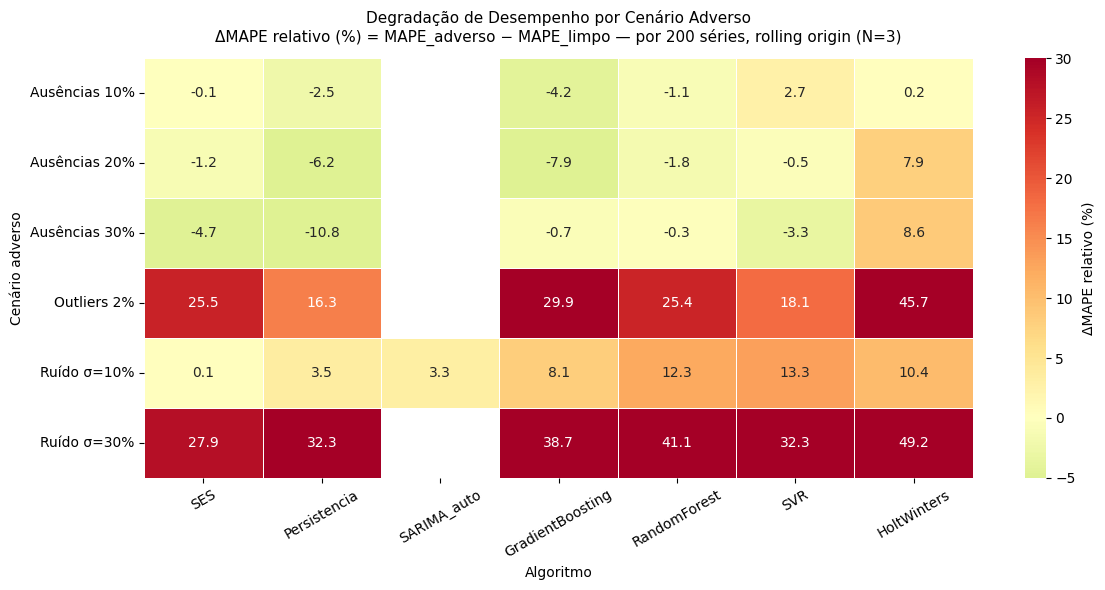

Figura salva.


In [12]:
import sys, warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from pathlib import Path

def _oe3_viz_setup():
    """Imports + df_all/pivot/mape_delta (idempotente)."""
    g = globals()
    if g.get('_OE3_VIZ_OK'):
        return
    _root = Path.cwd().resolve()
    for _candidate in (_root, *_root.parents):
        if (_candidate / 'src' / 'config.py').is_file():
            if str(_candidate) not in sys.path:
                sys.path.insert(0, str(_candidate))
            break
    from src.config import PROJECT_ROOT
    g['RESULTS_DIR'] = PROJECT_ROOT / 'results'
    g['ADV_DIR'] = g['RESULTS_DIR'] / 'adversos'
    BASELINE_FILE = g['RESULTS_DIR'] / 'baseline_limpo_200series.csv'
    ALL_RESULTS_FILE = g['ADV_DIR'] / 'todos_resultados_adversos.csv'
    _SKIP = {'todos_resultados_adversos', 'delta_mape_tabela'}
    g['ALGO_COLORS'] = {
        'HoltWinters': '#2196F3', 'SES': '#4CAF50', 'SARIMA_auto': '#FF9800',
        'GradientBoosting': '#9C27B0', 'RandomForest': '#F44336',
        'SVR': '#795548', 'Persistencia': '#607D8B',
    }
    g['SCENARIOS'] = [
        ('A_ruido_10pct', 'Ruído σ=10%'), ('A_ruido_30pct', 'Ruído σ=30%'),
        ('B_ausencias_10pct', 'Ausências 10%'), ('B_ausencias_20pct', 'Ausências 20%'),
        ('B_ausencias_30pct', 'Ausências 30%'), ('C_outliers_2pct', 'Outliers 2%'),
        ('C_outliers_5pct', 'Outliers 5%'), ('D_trunca_50pct', 'Truncamento 50%'),
        ('D_trunca_25pct', 'Truncamento 25%'),
    ]
    g['tipo_map'] = {
        'A': 'Ruído\ngaussiano', 'B': 'Ausências\naleatórias',
        'C': 'Outliers\npontuais', 'D': 'Truncamento\n(insuf. amostral)',
    }
    pivot_file = g['ADV_DIR'] / 'delta_mape_tabela.csv'
    if pivot_file.is_file() and 'pivot' not in g:
        g['pivot'] = pd.read_csv(pivot_file, index_col=0)
    if 'df_all' not in g:
        if ALL_RESULTS_FILE.is_file():
            g['df_all'] = pd.read_csv(ALL_RESULTS_FILE)
        else:
            partes = []
            for arq in sorted(g['ADV_DIR'].glob('*.csv')):
                if arq.stem in _SKIP:
                    continue
                d = pd.read_csv(arq)
                if 'cenario' not in d.columns:
                    d['cenario'] = arq.stem
                if 'descricao' not in d.columns:
                    d['descricao'] = arq.stem
                partes.append(d)
            if not partes:
                raise RuntimeError('Sem resultados em results/adversos/. Rode a seção ## 5.')
            g['df_all'] = pd.concat(partes, ignore_index=True)
    if not BASELINE_FILE.is_file():
        raise RuntimeError(f'Baseline ausente: {BASELINE_FILE}')
    g['df_base'] = pd.read_csv(BASELINE_FILE)
    g['base_mape'] = g['df_base'].groupby('modelo')['MAPE'].median().rename('MAPE_base')
    if 'mape_delta' not in g or 'pivot' not in g:
        mape_adv = (
            g['df_all'].groupby(['cenario', 'descricao', 'modelo'])['MAPE']
            .median().reset_index().rename(columns={'MAPE': 'MAPE_adv'})
        )
        g['mape_delta'] = mape_adv.merge(g['base_mape'].reset_index(), on='modelo')
        g['mape_delta']['DELTA_MAPE'] = g['mape_delta']['MAPE_adv'] - g['mape_delta']['MAPE_base']
        g['mape_delta']['DELTA_pct'] = g['mape_delta']['DELTA_MAPE'] / g['mape_delta']['MAPE_base'] * 100
        g['pivot'] = g['mape_delta'].pivot_table(
            index='descricao', columns='modelo', values='DELTA_pct'
        ).round(1)
        g['pivot'] = g['pivot'][g['pivot'].median().sort_values().index]
    g['modelos_ord'] = [m for m in g['base_mape'].sort_values().index if m in g['df_all']['modelo'].unique()]
    g['SEED'] = 42
    g['N_SERIES'] = 200
    g['H'] = 18
    g['MIN_TRAIN'] = 24
    g['N_ORIGINS'] = 3
    g['MODELS'] = {m: None for m in sorted(g['df_all']['modelo'].unique())}
    g['_OE3_VIZ_OK'] = True

_oe3_viz_setup()

# ── Fig 1: Heatmap de degradação ΔMAPE (%) ────────────────────────────────────
fig, ax = plt.subplots(figsize=(12, 6))

sns.heatmap(
    pivot,
    annot=True, fmt='.1f', cmap='RdYlGn_r',
    center=0, vmin=-5, vmax=30,
    linewidths=0.5, linecolor='white',
    ax=ax, cbar_kws={'label': 'ΔMAPE relativo (%)'},
)
ax.set_title('Degradação de Desempenho por Cenário Adverso\n'
             'ΔMAPE relativo (%) = MAPE_adverso − MAPE_limpo — por 200 séries, rolling origin (N=3)',
             fontsize=11, pad=12)
ax.set_xlabel('Algoritmo', fontsize=10)
ax.set_ylabel('Cenário adverso', fontsize=10)
ax.tick_params(axis='x', rotation=30)
ax.tick_params(axis='y', rotation=0)

plt.tight_layout()
fig.savefig(ADV_DIR / 'fig1_heatmap_delta_mape.png', dpi=150, bbox_inches='tight')
plt.show()
print('Figura salva.')


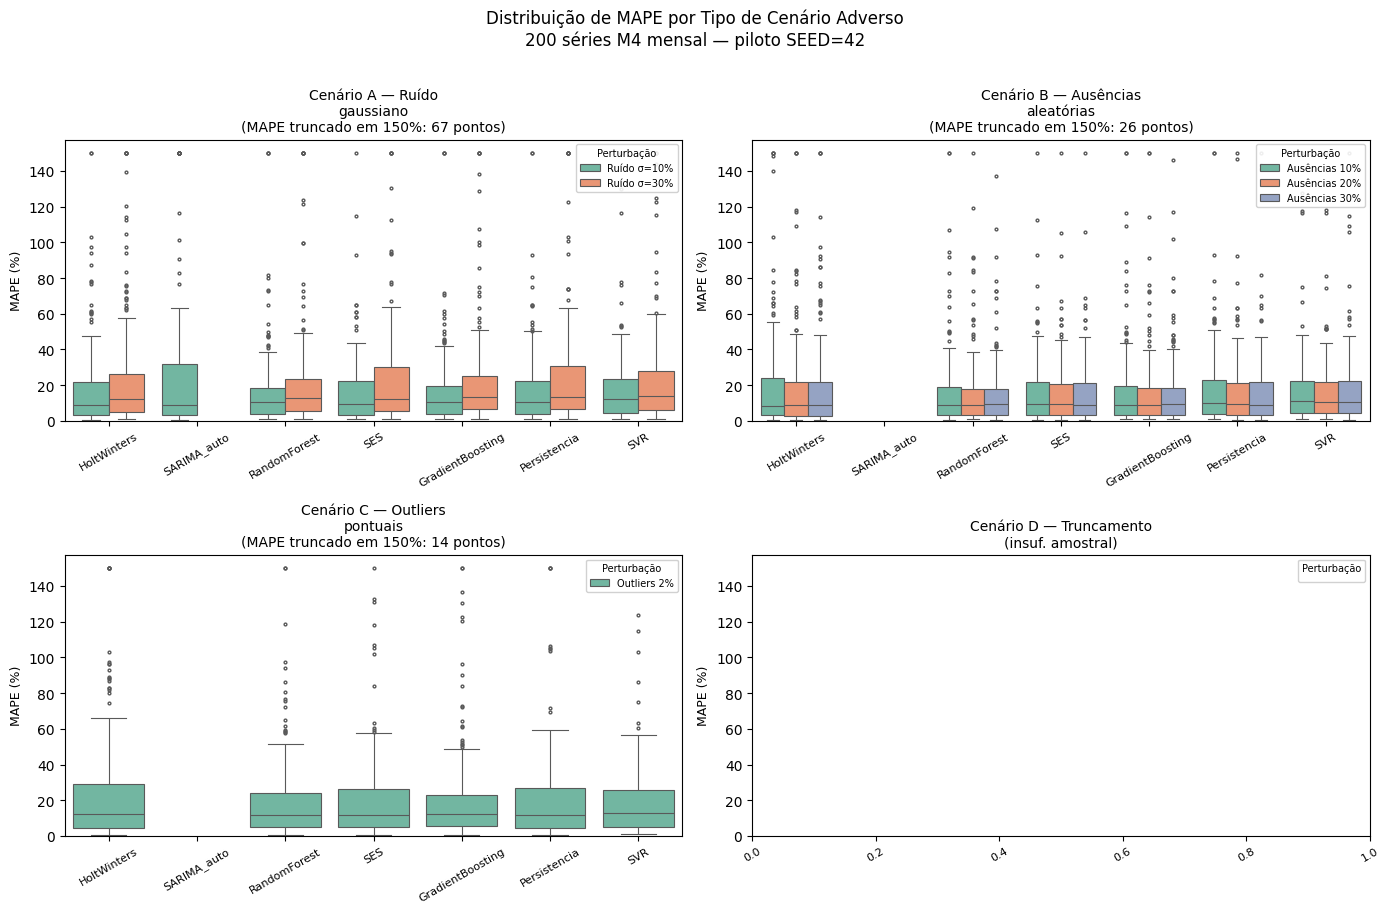

In [13]:
import sys, warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from pathlib import Path

def _oe3_viz_setup():
    """Imports + df_all/pivot/mape_delta (idempotente)."""
    g = globals()
    if g.get('_OE3_VIZ_OK'):
        return
    _root = Path.cwd().resolve()
    for _candidate in (_root, *_root.parents):
        if (_candidate / 'src' / 'config.py').is_file():
            if str(_candidate) not in sys.path:
                sys.path.insert(0, str(_candidate))
            break
    from src.config import PROJECT_ROOT
    g['RESULTS_DIR'] = PROJECT_ROOT / 'results'
    g['ADV_DIR'] = g['RESULTS_DIR'] / 'adversos'
    BASELINE_FILE = g['RESULTS_DIR'] / 'baseline_limpo_200series.csv'
    ALL_RESULTS_FILE = g['ADV_DIR'] / 'todos_resultados_adversos.csv'
    _SKIP = {'todos_resultados_adversos', 'delta_mape_tabela'}
    g['ALGO_COLORS'] = {
        'HoltWinters': '#2196F3', 'SES': '#4CAF50', 'SARIMA_auto': '#FF9800',
        'GradientBoosting': '#9C27B0', 'RandomForest': '#F44336',
        'SVR': '#795548', 'Persistencia': '#607D8B',
    }
    g['SCENARIOS'] = [
        ('A_ruido_10pct', 'Ruído σ=10%'), ('A_ruido_30pct', 'Ruído σ=30%'),
        ('B_ausencias_10pct', 'Ausências 10%'), ('B_ausencias_20pct', 'Ausências 20%'),
        ('B_ausencias_30pct', 'Ausências 30%'), ('C_outliers_2pct', 'Outliers 2%'),
        ('C_outliers_5pct', 'Outliers 5%'), ('D_trunca_50pct', 'Truncamento 50%'),
        ('D_trunca_25pct', 'Truncamento 25%'),
    ]
    g['tipo_map'] = {
        'A': 'Ruído\ngaussiano', 'B': 'Ausências\naleatórias',
        'C': 'Outliers\npontuais', 'D': 'Truncamento\n(insuf. amostral)',
    }
    pivot_file = g['ADV_DIR'] / 'delta_mape_tabela.csv'
    if pivot_file.is_file() and 'pivot' not in g:
        g['pivot'] = pd.read_csv(pivot_file, index_col=0)
    if 'df_all' not in g:
        if ALL_RESULTS_FILE.is_file():
            g['df_all'] = pd.read_csv(ALL_RESULTS_FILE)
        else:
            partes = []
            for arq in sorted(g['ADV_DIR'].glob('*.csv')):
                if arq.stem in _SKIP:
                    continue
                d = pd.read_csv(arq)
                if 'cenario' not in d.columns:
                    d['cenario'] = arq.stem
                if 'descricao' not in d.columns:
                    d['descricao'] = arq.stem
                partes.append(d)
            if not partes:
                raise RuntimeError('Sem resultados em results/adversos/. Rode a seção ## 5.')
            g['df_all'] = pd.concat(partes, ignore_index=True)
    if not BASELINE_FILE.is_file():
        raise RuntimeError(f'Baseline ausente: {BASELINE_FILE}')
    g['df_base'] = pd.read_csv(BASELINE_FILE)
    g['base_mape'] = g['df_base'].groupby('modelo')['MAPE'].median().rename('MAPE_base')
    if 'mape_delta' not in g or 'pivot' not in g:
        mape_adv = (
            g['df_all'].groupby(['cenario', 'descricao', 'modelo'])['MAPE']
            .median().reset_index().rename(columns={'MAPE': 'MAPE_adv'})
        )
        g['mape_delta'] = mape_adv.merge(g['base_mape'].reset_index(), on='modelo')
        g['mape_delta']['DELTA_MAPE'] = g['mape_delta']['MAPE_adv'] - g['mape_delta']['MAPE_base']
        g['mape_delta']['DELTA_pct'] = g['mape_delta']['DELTA_MAPE'] / g['mape_delta']['MAPE_base'] * 100
        g['pivot'] = g['mape_delta'].pivot_table(
            index='descricao', columns='modelo', values='DELTA_pct'
        ).round(1)
        g['pivot'] = g['pivot'][g['pivot'].median().sort_values().index]
    g['modelos_ord'] = [m for m in g['base_mape'].sort_values().index if m in g['df_all']['modelo'].unique()]
    g['SEED'] = 42
    g['N_SERIES'] = 200
    g['H'] = 18
    g['MIN_TRAIN'] = 24
    g['N_ORIGINS'] = 3
    g['MODELS'] = {m: None for m in sorted(g['df_all']['modelo'].unique())}
    g['_OE3_VIZ_OK'] = True

_oe3_viz_setup()

# ── Fig 2: Boxplot MAPE por família de cenário ────────────────────────────────
# Classifica cenários por tipo
tipo_map = {
    'A': 'Ruído\ngaussiano',
    'B': 'Ausências\naleatórias',
    'C': 'Outliers\npontuais',
    'D': 'Truncamento\n(insuf. amostral)',
}
df_all['tipo'] = df_all['cenario'].str[0].map(tipo_map)

fig, axes = plt.subplots(2, 2, figsize=(14, 9), sharey=False)
axes = axes.flatten()

MAPE_CAP_VIZ = 150  # corta explosões de MAPE (y≈0) só para o gráfico

for ax, (letra, tipo_label) in zip(axes, tipo_map.items()):
    sub = df_all[df_all['cenario'].str.startswith(letra)].copy()
    n_clip = int((sub['MAPE'] > MAPE_CAP_VIZ).sum())
    sub['MAPE_plot'] = sub['MAPE'].clip(upper=MAPE_CAP_VIZ)

    sns.boxplot(
        data=sub, x='modelo', y='MAPE_plot',
        order=modelos_ord,
        hue='descricao', palette='Set2',
        ax=ax, fliersize=2, linewidth=0.8,
    )
    titulo = f'Cenário {letra} — {tipo_label}'
    if n_clip:
        titulo += f'\n(MAPE truncado em {MAPE_CAP_VIZ}%: {n_clip} pontos)'
    ax.set_title(titulo, fontsize=10)
    ax.set_xlabel('')
    ax.set_ylabel('MAPE (%)', fontsize=9)
    ax.tick_params(axis='x', rotation=30, labelsize=8)
    ax.legend(title='Perturbação', fontsize=7, title_fontsize=7,
              loc='upper right', ncol=1, framealpha=0.9)
    ax.set_ylim(0, MAPE_CAP_VIZ * 1.05)
    ax.yaxis.set_major_formatter(mticker.FormatStrFormatter('%.0f'))

fig.suptitle('Distribuição de MAPE por Tipo de Cenário Adverso\n'
             '200 séries M4 mensal — piloto SEED=42', fontsize=12, y=1.01)
plt.tight_layout()
fig.savefig(ADV_DIR / 'fig2_boxplot_mape_cenarios.png', dpi=150, bbox_inches='tight')
plt.show()


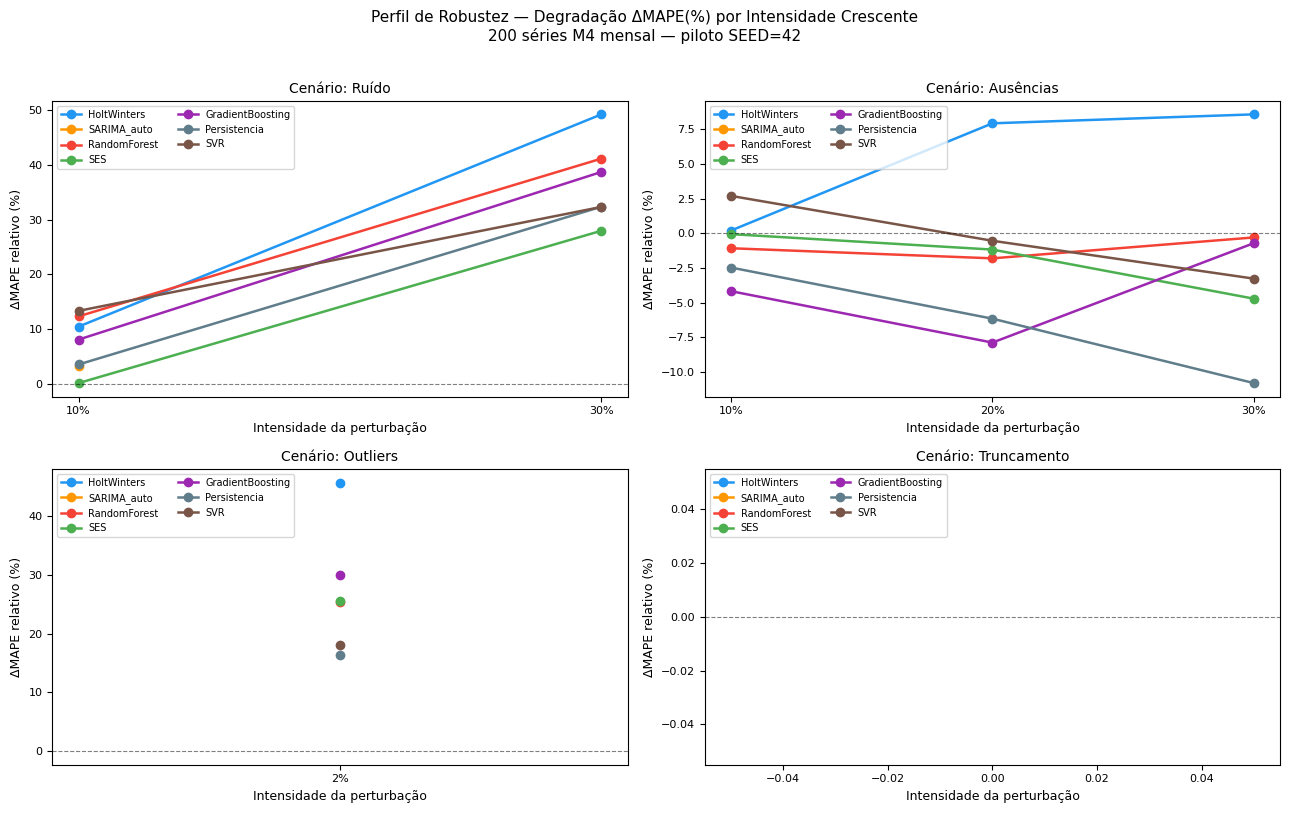

In [14]:
import sys, warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from pathlib import Path

def _oe3_viz_setup():
    """Imports + df_all/pivot/mape_delta (idempotente)."""
    g = globals()
    if g.get('_OE3_VIZ_OK'):
        return
    _root = Path.cwd().resolve()
    for _candidate in (_root, *_root.parents):
        if (_candidate / 'src' / 'config.py').is_file():
            if str(_candidate) not in sys.path:
                sys.path.insert(0, str(_candidate))
            break
    from src.config import PROJECT_ROOT
    g['RESULTS_DIR'] = PROJECT_ROOT / 'results'
    g['ADV_DIR'] = g['RESULTS_DIR'] / 'adversos'
    BASELINE_FILE = g['RESULTS_DIR'] / 'baseline_limpo_200series.csv'
    ALL_RESULTS_FILE = g['ADV_DIR'] / 'todos_resultados_adversos.csv'
    _SKIP = {'todos_resultados_adversos', 'delta_mape_tabela'}
    g['ALGO_COLORS'] = {
        'HoltWinters': '#2196F3', 'SES': '#4CAF50', 'SARIMA_auto': '#FF9800',
        'GradientBoosting': '#9C27B0', 'RandomForest': '#F44336',
        'SVR': '#795548', 'Persistencia': '#607D8B',
    }
    g['SCENARIOS'] = [
        ('A_ruido_10pct', 'Ruído σ=10%'), ('A_ruido_30pct', 'Ruído σ=30%'),
        ('B_ausencias_10pct', 'Ausências 10%'), ('B_ausencias_20pct', 'Ausências 20%'),
        ('B_ausencias_30pct', 'Ausências 30%'), ('C_outliers_2pct', 'Outliers 2%'),
        ('C_outliers_5pct', 'Outliers 5%'), ('D_trunca_50pct', 'Truncamento 50%'),
        ('D_trunca_25pct', 'Truncamento 25%'),
    ]
    g['tipo_map'] = {
        'A': 'Ruído\ngaussiano', 'B': 'Ausências\naleatórias',
        'C': 'Outliers\npontuais', 'D': 'Truncamento\n(insuf. amostral)',
    }
    pivot_file = g['ADV_DIR'] / 'delta_mape_tabela.csv'
    if pivot_file.is_file() and 'pivot' not in g:
        g['pivot'] = pd.read_csv(pivot_file, index_col=0)
    if 'df_all' not in g:
        if ALL_RESULTS_FILE.is_file():
            g['df_all'] = pd.read_csv(ALL_RESULTS_FILE)
        else:
            partes = []
            for arq in sorted(g['ADV_DIR'].glob('*.csv')):
                if arq.stem in _SKIP:
                    continue
                d = pd.read_csv(arq)
                if 'cenario' not in d.columns:
                    d['cenario'] = arq.stem
                if 'descricao' not in d.columns:
                    d['descricao'] = arq.stem
                partes.append(d)
            if not partes:
                raise RuntimeError('Sem resultados em results/adversos/. Rode a seção ## 5.')
            g['df_all'] = pd.concat(partes, ignore_index=True)
    if not BASELINE_FILE.is_file():
        raise RuntimeError(f'Baseline ausente: {BASELINE_FILE}')
    g['df_base'] = pd.read_csv(BASELINE_FILE)
    g['base_mape'] = g['df_base'].groupby('modelo')['MAPE'].median().rename('MAPE_base')
    if 'mape_delta' not in g or 'pivot' not in g:
        mape_adv = (
            g['df_all'].groupby(['cenario', 'descricao', 'modelo'])['MAPE']
            .median().reset_index().rename(columns={'MAPE': 'MAPE_adv'})
        )
        g['mape_delta'] = mape_adv.merge(g['base_mape'].reset_index(), on='modelo')
        g['mape_delta']['DELTA_MAPE'] = g['mape_delta']['MAPE_adv'] - g['mape_delta']['MAPE_base']
        g['mape_delta']['DELTA_pct'] = g['mape_delta']['DELTA_MAPE'] / g['mape_delta']['MAPE_base'] * 100
        g['pivot'] = g['mape_delta'].pivot_table(
            index='descricao', columns='modelo', values='DELTA_pct'
        ).round(1)
        g['pivot'] = g['pivot'][g['pivot'].median().sort_values().index]
    g['modelos_ord'] = [m for m in g['base_mape'].sort_values().index if m in g['df_all']['modelo'].unique()]
    g['SEED'] = 42
    g['N_SERIES'] = 200
    g['H'] = 18
    g['MIN_TRAIN'] = 24
    g['N_ORIGINS'] = 3
    g['MODELS'] = {m: None for m in sorted(g['df_all']['modelo'].unique())}
    g['_OE3_VIZ_OK'] = True

_oe3_viz_setup()

# ── Fig 3: Perfil de robustez — ΔMAPE médio por intensidade crescente ─────────
# Cenários com intensidade crescente dentro do mesmo tipo
progressao = {
    'Ruído':      [('A_ruido_10pct','10%'), ('A_ruido_30pct','30%')],
    'Ausências':  [('B_ausencias_10pct','10%'), ('B_ausencias_20pct','20%'), ('B_ausencias_30pct','30%')],
    'Outliers':   [('C_outliers_2pct','2%'), ('C_outliers_5pct','5%')],
    'Truncamento':[('D_trunca_50pct','50%'), ('D_trunca_25pct','25%')],
}

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
axes = axes.flatten()

for ax, (tipo, cenarios) in zip(axes, progressao.items()):
    for modelo in modelos_ord:
        xs, ys = [], []
        base_m = base_mape.get(modelo, np.nan)
        for (cid, label) in cenarios:
            sub = mape_delta[(mape_delta['cenario'] == cid) & (mape_delta['modelo'] == modelo)]
            if not sub.empty:
                xs.append(label)
                ys.append(sub['DELTA_pct'].values[0])
        color = ALGO_COLORS.get(modelo, 'gray')
        ax.plot(xs, ys, marker='o', label=modelo, color=color, linewidth=1.8)

    ax.axhline(0, color='black', linewidth=0.8, linestyle='--', alpha=0.5)
    ax.set_title(f'Cenário: {tipo}', fontsize=10)
    ax.set_ylabel('ΔMAPE relativo (%)', fontsize=9)
    ax.set_xlabel('Intensidade da perturbação', fontsize=9)
    ax.tick_params(labelsize=8)
    ax.legend(fontsize=7, ncol=2, loc='upper left')

fig.suptitle('Perfil de Robustez — Degradação ΔMAPE(%) por Intensidade Crescente\n'
             '200 séries M4 mensal — piloto SEED=42', fontsize=11, y=1.01)
plt.tight_layout()
fig.savefig(ADV_DIR / 'fig3_perfil_robustez.png', dpi=150, bbox_inches='tight')
plt.show()


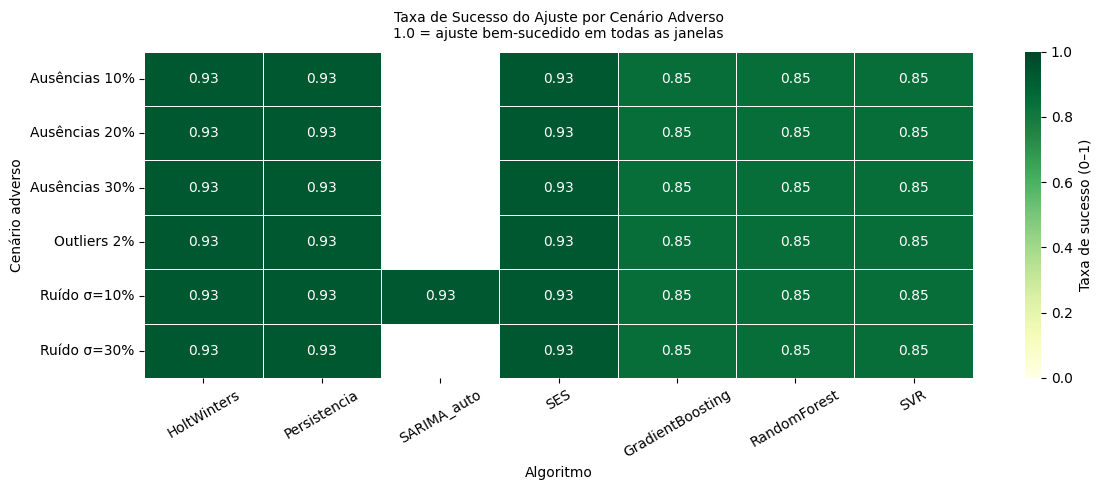

In [15]:
import sys, warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from pathlib import Path

def _oe3_viz_setup():
    """Imports + df_all/pivot/mape_delta (idempotente)."""
    g = globals()
    if g.get('_OE3_VIZ_OK'):
        return
    _root = Path.cwd().resolve()
    for _candidate in (_root, *_root.parents):
        if (_candidate / 'src' / 'config.py').is_file():
            if str(_candidate) not in sys.path:
                sys.path.insert(0, str(_candidate))
            break
    from src.config import PROJECT_ROOT
    g['RESULTS_DIR'] = PROJECT_ROOT / 'results'
    g['ADV_DIR'] = g['RESULTS_DIR'] / 'adversos'
    BASELINE_FILE = g['RESULTS_DIR'] / 'baseline_limpo_200series.csv'
    ALL_RESULTS_FILE = g['ADV_DIR'] / 'todos_resultados_adversos.csv'
    _SKIP = {'todos_resultados_adversos', 'delta_mape_tabela'}
    g['ALGO_COLORS'] = {
        'HoltWinters': '#2196F3', 'SES': '#4CAF50', 'SARIMA_auto': '#FF9800',
        'GradientBoosting': '#9C27B0', 'RandomForest': '#F44336',
        'SVR': '#795548', 'Persistencia': '#607D8B',
    }
    g['SCENARIOS'] = [
        ('A_ruido_10pct', 'Ruído σ=10%'), ('A_ruido_30pct', 'Ruído σ=30%'),
        ('B_ausencias_10pct', 'Ausências 10%'), ('B_ausencias_20pct', 'Ausências 20%'),
        ('B_ausencias_30pct', 'Ausências 30%'), ('C_outliers_2pct', 'Outliers 2%'),
        ('C_outliers_5pct', 'Outliers 5%'), ('D_trunca_50pct', 'Truncamento 50%'),
        ('D_trunca_25pct', 'Truncamento 25%'),
    ]
    g['tipo_map'] = {
        'A': 'Ruído\ngaussiano', 'B': 'Ausências\naleatórias',
        'C': 'Outliers\npontuais', 'D': 'Truncamento\n(insuf. amostral)',
    }
    pivot_file = g['ADV_DIR'] / 'delta_mape_tabela.csv'
    if pivot_file.is_file() and 'pivot' not in g:
        g['pivot'] = pd.read_csv(pivot_file, index_col=0)
    if 'df_all' not in g:
        if ALL_RESULTS_FILE.is_file():
            g['df_all'] = pd.read_csv(ALL_RESULTS_FILE)
        else:
            partes = []
            for arq in sorted(g['ADV_DIR'].glob('*.csv')):
                if arq.stem in _SKIP:
                    continue
                d = pd.read_csv(arq)
                if 'cenario' not in d.columns:
                    d['cenario'] = arq.stem
                if 'descricao' not in d.columns:
                    d['descricao'] = arq.stem
                partes.append(d)
            if not partes:
                raise RuntimeError('Sem resultados em results/adversos/. Rode a seção ## 5.')
            g['df_all'] = pd.concat(partes, ignore_index=True)
    if not BASELINE_FILE.is_file():
        raise RuntimeError(f'Baseline ausente: {BASELINE_FILE}')
    g['df_base'] = pd.read_csv(BASELINE_FILE)
    g['base_mape'] = g['df_base'].groupby('modelo')['MAPE'].median().rename('MAPE_base')
    if 'mape_delta' not in g or 'pivot' not in g:
        mape_adv = (
            g['df_all'].groupby(['cenario', 'descricao', 'modelo'])['MAPE']
            .median().reset_index().rename(columns={'MAPE': 'MAPE_adv'})
        )
        g['mape_delta'] = mape_adv.merge(g['base_mape'].reset_index(), on='modelo')
        g['mape_delta']['DELTA_MAPE'] = g['mape_delta']['MAPE_adv'] - g['mape_delta']['MAPE_base']
        g['mape_delta']['DELTA_pct'] = g['mape_delta']['DELTA_MAPE'] / g['mape_delta']['MAPE_base'] * 100
        g['pivot'] = g['mape_delta'].pivot_table(
            index='descricao', columns='modelo', values='DELTA_pct'
        ).round(1)
        g['pivot'] = g['pivot'][g['pivot'].median().sort_values().index]
    g['modelos_ord'] = [m for m in g['base_mape'].sort_values().index if m in g['df_all']['modelo'].unique()]
    g['SEED'] = 42
    g['N_SERIES'] = 200
    g['H'] = 18
    g['MIN_TRAIN'] = 24
    g['N_ORIGINS'] = 3
    g['MODELS'] = {m: None for m in sorted(g['df_all']['modelo'].unique())}
    g['_OE3_VIZ_OK'] = True

_oe3_viz_setup()

# ── Fig 4: Taxa de sucesso por cenário e modelo ───────────────────────────────
taxa_adv = (
    df_all.groupby(['cenario','descricao','modelo'])['success_rate']
    .mean()
    .reset_index()
)
pivot_taxa = taxa_adv.pivot_table(
    index='descricao', columns='modelo', values='success_rate'
).round(2)
pivot_taxa = pivot_taxa[pivot_taxa.mean().sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(12, 5))
sns.heatmap(
    pivot_taxa, annot=True, fmt='.2f',
    cmap='YlGn', vmin=0, vmax=1,
    linewidths=0.5, linecolor='white', ax=ax,
    cbar_kws={'label': 'Taxa de sucesso (0–1)'},
)
ax.set_title('Taxa de Sucesso do Ajuste por Cenário Adverso\n'
             '1.0 = ajuste bem-sucedido em todas as janelas', fontsize=10, pad=10)
ax.set_xlabel('Algoritmo'); ax.set_ylabel('Cenário adverso')
ax.tick_params(axis='x', rotation=30)
ax.tick_params(axis='y', rotation=0)
plt.tight_layout()
fig.savefig(ADV_DIR / 'fig4_taxa_sucesso.png', dpi=150, bbox_inches='tight')
plt.show()


## 8. Tabela-resumo consolidada (para a dissertação)

In [17]:
import sys, warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from pathlib import Path

def _oe3_viz_setup():
    """Imports + df_all/pivot/mape_delta (idempotente)."""
    g = globals()
    if g.get('_OE3_VIZ_OK'):
        return
    _root = Path.cwd().resolve()
    for _candidate in (_root, *_root.parents):
        if (_candidate / 'src' / 'config.py').is_file():
            if str(_candidate) not in sys.path:
                sys.path.insert(0, str(_candidate))
            break
    from src.config import PROJECT_ROOT
    g['RESULTS_DIR'] = PROJECT_ROOT / 'results'
    g['ADV_DIR'] = g['RESULTS_DIR'] / 'adversos'
    BASELINE_FILE = g['RESULTS_DIR'] / 'baseline_limpo_200series.csv'
    ALL_RESULTS_FILE = g['ADV_DIR'] / 'todos_resultados_adversos.csv'
    _SKIP = {'todos_resultados_adversos', 'delta_mape_tabela'}
    g['ALGO_COLORS'] = {
        'HoltWinters': '#2196F3', 'SES': '#4CAF50', 'SARIMA_auto': '#FF9800',
        'GradientBoosting': '#9C27B0', 'RandomForest': '#F44336',
        'SVR': '#795548', 'Persistencia': '#607D8B',
    }
    g['SCENARIOS'] = [
        ('A_ruido_10pct', 'Ruído σ=10%'), ('A_ruido_30pct', 'Ruído σ=30%'),
        ('B_ausencias_10pct', 'Ausências 10%'), ('B_ausencias_20pct', 'Ausências 20%'),
        ('B_ausencias_30pct', 'Ausências 30%'), ('C_outliers_2pct', 'Outliers 2%'),
        ('C_outliers_5pct', 'Outliers 5%'), ('D_trunca_50pct', 'Truncamento 50%'),
        ('D_trunca_25pct', 'Truncamento 25%'),
    ]
    g['tipo_map'] = {
        'A': 'Ruído\ngaussiano', 'B': 'Ausências\naleatórias',
        'C': 'Outliers\npontuais', 'D': 'Truncamento\n(insuf. amostral)',
    }
    pivot_file = g['ADV_DIR'] / 'delta_mape_tabela.csv'
    if pivot_file.is_file() and 'pivot' not in g:
        g['pivot'] = pd.read_csv(pivot_file, index_col=0)
    if 'df_all' not in g:
        if ALL_RESULTS_FILE.is_file():
            g['df_all'] = pd.read_csv(ALL_RESULTS_FILE)
        else:
            partes = []
            for arq in sorted(g['ADV_DIR'].glob('*.csv')):
                if arq.stem in _SKIP:
                    continue
                d = pd.read_csv(arq)
                if 'cenario' not in d.columns:
                    d['cenario'] = arq.stem
                if 'descricao' not in d.columns:
                    d['descricao'] = arq.stem
                partes.append(d)
            if not partes:
                raise RuntimeError('Sem resultados em results/adversos/. Rode a seção ## 5.')
            g['df_all'] = pd.concat(partes, ignore_index=True)
    if not BASELINE_FILE.is_file():
        raise RuntimeError(f'Baseline ausente: {BASELINE_FILE}')
    g['df_base'] = pd.read_csv(BASELINE_FILE)
    g['base_mape'] = g['df_base'].groupby('modelo')['MAPE'].median().rename('MAPE_base')
    if 'mape_delta' not in g or 'pivot' not in g:
        mape_adv = (
            g['df_all'].groupby(['cenario', 'descricao', 'modelo'])['MAPE']
            .median().reset_index().rename(columns={'MAPE': 'MAPE_adv'})
        )
        g['mape_delta'] = mape_adv.merge(g['base_mape'].reset_index(), on='modelo')
        g['mape_delta']['DELTA_MAPE'] = g['mape_delta']['MAPE_adv'] - g['mape_delta']['MAPE_base']
        g['mape_delta']['DELTA_pct'] = g['mape_delta']['DELTA_MAPE'] / g['mape_delta']['MAPE_base'] * 100
        g['pivot'] = g['mape_delta'].pivot_table(
            index='descricao', columns='modelo', values='DELTA_pct'
        ).round(1)
        g['pivot'] = g['pivot'][g['pivot'].median().sort_values().index]
    g['modelos_ord'] = [m for m in g['base_mape'].sort_values().index if m in g['df_all']['modelo'].unique()]
    g['SEED'] = 42
    g['N_SERIES'] = 200
    g['H'] = 18
    g['MIN_TRAIN'] = 24
    g['N_ORIGINS'] = 3
    g['MODELS'] = {m: None for m in sorted(g['df_all']['modelo'].unique())}
    g['_OE3_VIZ_OK'] = True

_oe3_viz_setup()

# Tabela final: MAPE limpo + MAPE adverso + ΔMAPE relativo para cada cenário
resumo_rows = []
for modelo in modelos_ord:
    row = {'Modelo': modelo, 'MAPE_limpo': round(base_mape.get(modelo, np.nan), 2)}
    for (cid, desc) in SCENARIOS:
        sub = mape_delta[(mape_delta['cenario'] == cid) & (mape_delta['modelo'] == modelo)]
        if not sub.empty:
            row[f'ΔMAPE_{cid}'] = round(sub['DELTA_pct'].values[0], 1)
    resumo_rows.append(row)

df_resumo = pd.DataFrame(resumo_rows).set_index('Modelo')
# Ordena pela robustez geral: menor soma de |ΔMAPE| entre cenários
delta_cols = [c for c in df_resumo.columns if c.startswith('ΔMAPE')]
df_resumo['robustez_score'] = df_resumo[delta_cols].abs().mean(axis=1)
df_resumo = df_resumo.sort_values('robustez_score')

print('Tabela-resumo (ordenada por robustez geral — menor ΔMAPE médio absoluto):')
print(df_resumo.to_string())

df_resumo.to_csv(ADV_DIR / 'tabela_resumo_adversos.csv')
print(f'\nSalvo em {ADV_DIR / "tabela_resumo_adversos.csv"}')


Tabela-resumo (ordenada por robustez geral — menor ΔMAPE médio absoluto):
                  MAPE_limpo  ΔMAPE_A_ruido_10pct  ΔMAPE_A_ruido_30pct  ΔMAPE_B_ausencias_10pct  ΔMAPE_B_ausencias_20pct  ΔMAPE_B_ausencias_30pct  ΔMAPE_C_outliers_2pct  robustez_score
Modelo                                                                                                                                                                                  
SARIMA_auto             8.38                  3.3                  NaN                      NaN                      NaN                      NaN                    NaN        3.300000
SES                     9.49                  0.1                 27.9                     -0.1                     -1.2                     -4.7                   25.5        9.916667
SVR                    10.71                 13.3                 32.3                      2.7                     -0.5                     -3.3                   18.1       11.700000
P

## 9. Síntese interpretativa

Célula de texto gerada automaticamente para apoiar a escrita da dissertação.

In [19]:
import sys, warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from pathlib import Path

def _oe3_viz_setup():
    """Imports + df_all/pivot/mape_delta (idempotente)."""
    g = globals()
    if g.get('_OE3_VIZ_OK'):
        return
    _root = Path.cwd().resolve()
    for _candidate in (_root, *_root.parents):
        if (_candidate / 'src' / 'config.py').is_file():
            if str(_candidate) not in sys.path:
                sys.path.insert(0, str(_candidate))
            break
    from src.config import PROJECT_ROOT
    g['RESULTS_DIR'] = PROJECT_ROOT / 'results'
    g['ADV_DIR'] = g['RESULTS_DIR'] / 'adversos'
    BASELINE_FILE = g['RESULTS_DIR'] / 'baseline_limpo_200series.csv'
    ALL_RESULTS_FILE = g['ADV_DIR'] / 'todos_resultados_adversos.csv'
    _SKIP = {'todos_resultados_adversos', 'delta_mape_tabela'}
    g['ALGO_COLORS'] = {
        'HoltWinters': '#2196F3', 'SES': '#4CAF50', 'SARIMA_auto': '#FF9800',
        'GradientBoosting': '#9C27B0', 'RandomForest': '#F44336',
        'SVR': '#795548', 'Persistencia': '#607D8B',
    }
    g['SCENARIOS'] = [
        ('A_ruido_10pct', 'Ruído σ=10%'), ('A_ruido_30pct', 'Ruído σ=30%'),
        ('B_ausencias_10pct', 'Ausências 10%'), ('B_ausencias_20pct', 'Ausências 20%'),
        ('B_ausencias_30pct', 'Ausências 30%'), ('C_outliers_2pct', 'Outliers 2%'),
        ('C_outliers_5pct', 'Outliers 5%'), ('D_trunca_50pct', 'Truncamento 50%'),
        ('D_trunca_25pct', 'Truncamento 25%'),
    ]
    g['tipo_map'] = {
        'A': 'Ruído\ngaussiano', 'B': 'Ausências\naleatórias',
        'C': 'Outliers\npontuais', 'D': 'Truncamento\n(insuf. amostral)',
    }
    pivot_file = g['ADV_DIR'] / 'delta_mape_tabela.csv'
    if pivot_file.is_file() and 'pivot' not in g:
        g['pivot'] = pd.read_csv(pivot_file, index_col=0)
    if 'df_all' not in g:
        if ALL_RESULTS_FILE.is_file():
            g['df_all'] = pd.read_csv(ALL_RESULTS_FILE)
        else:
            partes = []
            for arq in sorted(g['ADV_DIR'].glob('*.csv')):
                if arq.stem in _SKIP:
                    continue
                d = pd.read_csv(arq)
                if 'cenario' not in d.columns:
                    d['cenario'] = arq.stem
                if 'descricao' not in d.columns:
                    d['descricao'] = arq.stem
                partes.append(d)
            if not partes:
                raise RuntimeError('Sem resultados em results/adversos/. Rode a seção ## 5.')
            g['df_all'] = pd.concat(partes, ignore_index=True)
    if not BASELINE_FILE.is_file():
        raise RuntimeError(f'Baseline ausente: {BASELINE_FILE}')
    g['df_base'] = pd.read_csv(BASELINE_FILE)
    g['base_mape'] = g['df_base'].groupby('modelo')['MAPE'].median().rename('MAPE_base')
    if 'mape_delta' not in g or 'pivot' not in g:
        mape_adv = (
            g['df_all'].groupby(['cenario', 'descricao', 'modelo'])['MAPE']
            .median().reset_index().rename(columns={'MAPE': 'MAPE_adv'})
        )
        g['mape_delta'] = mape_adv.merge(g['base_mape'].reset_index(), on='modelo')
        g['mape_delta']['DELTA_MAPE'] = g['mape_delta']['MAPE_adv'] - g['mape_delta']['MAPE_base']
        g['mape_delta']['DELTA_pct'] = g['mape_delta']['DELTA_MAPE'] / g['mape_delta']['MAPE_base'] * 100
        g['pivot'] = g['mape_delta'].pivot_table(
            index='descricao', columns='modelo', values='DELTA_pct'
        ).round(1)
        g['pivot'] = g['pivot'][g['pivot'].median().sort_values().index]
    g['modelos_ord'] = [m for m in g['base_mape'].sort_values().index if m in g['df_all']['modelo'].unique()]
    g['SEED'] = 42
    g['N_SERIES'] = 200
    g['H'] = 18
    g['MIN_TRAIN'] = 24
    g['N_ORIGINS'] = 3
    g['MODELS'] = {m: None for m in sorted(g['df_all']['modelo'].unique())}
    g['_OE3_VIZ_OK'] = True

_oe3_viz_setup()

print('=== SÍNTESE AUTOMÁTICA DOS RESULTADOS ===')
print()

mais_robusto  = df_resumo['robustez_score'].idxmin()
menos_robusto = df_resumo['robustez_score'].idxmax()

print(f'Algoritmo mais robusto (menor ΔMAPE médio):  {mais_robusto}')
print(f'Algoritmo menos robusto (maior ΔMAPE médio): {menos_robusto}')
print()

for letra, tipo_label in tipo_map.items():
    cids = [c for c, _ in SCENARIOS if c.startswith(letra)]
    sub = mape_delta[mape_delta['cenario'].isin(cids)]
    if sub.empty:
        print(f'Cenário {letra} ({tipo_label.strip()}): sem dados ainda '
              f'(faltam cenários {cids} — rode a seção ## 5)')
        continue
    agg = sub.groupby('modelo')['DELTA_pct'].mean()
    worst_model = agg.idxmax()
    best_model = agg.idxmin()
    print(f'Cenário {letra} ({tipo_label.strip()}): mais sensível → {worst_model} | '
          f'mais estável → {best_model}')

print()
print('Arquivos gerados em:', ADV_DIR.resolve())
for f in sorted(ADV_DIR.glob('*.csv')) + sorted(ADV_DIR.glob('*.png')):
    print(' ', f.name)


=== SÍNTESE AUTOMÁTICA DOS RESULTADOS ===

Algoritmo mais robusto (menor ΔMAPE médio):  SARIMA_auto
Algoritmo menos robusto (maior ΔMAPE médio): HoltWinters

Cenário A (Ruído
gaussiano): mais sensível → HoltWinters | mais estável → SARIMA_auto
Cenário B (Ausências
aleatórias): mais sensível → HoltWinters | mais estável → Persistencia
Cenário C (Outliers
pontuais): mais sensível → HoltWinters | mais estável → Persistencia
Cenário D (Truncamento
(insuf. amostral)): sem dados ainda (faltam cenários ['D_trunca_50pct', 'D_trunca_25pct'] — rode a seção ## 5)

Arquivos gerados em: C:\Users\Usuario\Desktop\Mestrado\Mestrado - aula\dissertação\autopred\results\adversos
  A_ruido_10pct.csv
  A_ruido_30pct.csv
  B_ausencias_10pct.csv
  B_ausencias_20pct.csv
  B_ausencias_30pct.csv
  C_outliers_2pct.csv
  delta_mape_tabela.csv
  tabela_resumo_adversos.csv
  fig1_heatmap_delta_mape.png
  fig2_boxplot_mape_cenarios.png
  fig3_perfil_robustez.png
  fig4_taxa_sucesso.png


---
## Registro de execução

In [21]:
import json
import sys
import platform
from pathlib import Path

import pandas as pd
import sklearn
import statsmodels

if 'ADV_DIR' not in globals():
    _root = Path.cwd().resolve()
    for _candidate in (_root, *_root.parents):
        if (_candidate / 'src' / 'config.py').is_file():
            if str(_candidate) not in sys.path:
                sys.path.insert(0, str(_candidate))
            break
    from src.config import PROJECT_ROOT
    ADV_DIR = PROJECT_ROOT / 'results' / 'adversos'
    SEED, N_SERIES, H, MIN_TRAIN, N_ORIGINS = 42, 200, 18, 24, 3
    SCENARIOS = [
        ('A_ruido_10pct', 'Ruído σ=10%'), ('A_ruido_30pct', 'Ruído σ=30%'),
        ('B_ausencias_10pct', 'Ausências 10%'), ('B_ausencias_20pct', 'Ausências 20%'),
        ('B_ausencias_30pct', 'Ausências 30%'), ('C_outliers_2pct', 'Outliers 2%'),
        ('C_outliers_5pct', 'Outliers 5%'), ('D_trunca_50pct', 'Truncamento 50%'),
        ('D_trunca_25pct', 'Truncamento 25%'),
    ]
    MODELS = {m: None for m in [
        'Persistencia', 'HoltWinters', 'SES', 'RandomForest',
        'GradientBoosting', 'SVR',
    ]}

ADV_DIR.mkdir(parents=True, exist_ok=True)

log = {
    'notebook': '08_cenarios_adversos.ipynb',
    'objetivo_especifico': 'OE3',
    'data_execucao': pd.Timestamp.now().isoformat(),
    'python': platform.python_version(),
    'sklearn': sklearn.__version__,
    'statsmodels': statsmodels.__version__,
    'seed': SEED,
    'n_series': N_SERIES,
    'h': H,
    'min_train': MIN_TRAIN,
    'n_origins': N_ORIGINS,
    'n_cenarios': len(SCENARIOS),
    'modelos': list(MODELS.keys()),
    'cenarios': [c for c, _ in SCENARIOS],
}

log_path = ADV_DIR / 'execution_log.json'
with open(log_path, 'w', encoding='utf-8') as f:
    json.dump(log, f, indent=2, ensure_ascii=False, default=str)

print(json.dumps(log, indent=2, ensure_ascii=False, default=str))
print(f'\nSalvo em {log_path}')

{
  "notebook": "08_cenarios_adversos.ipynb",
  "objetivo_especifico": "OE3",
  "data_execucao": "2026-05-24T19:06:28.929404",
  "python": "3.11.0",
  "sklearn": "1.8.0",
  "statsmodels": "0.14.6",
  "seed": 42,
  "n_series": 200,
  "h": 18,
  "min_train": 24,
  "n_origins": 3,
  "n_cenarios": 9,
  "modelos": [
    "GradientBoosting",
    "HoltWinters",
    "Persistencia",
    "RandomForest",
    "SARIMA_auto",
    "SES",
    "SVR"
  ],
  "cenarios": [
    "A_ruido_10pct",
    "A_ruido_30pct",
    "B_ausencias_10pct",
    "B_ausencias_20pct",
    "B_ausencias_30pct",
    "C_outliers_2pct",
    "C_outliers_5pct",
    "D_trunca_50pct",
    "D_trunca_25pct"
  ]
}

Salvo em C:\Users\Usuario\Desktop\Mestrado\Mestrado - aula\dissertação\autopred\results\adversos\execution_log.json
